# **Project:- Customer Churn & Retention Analysis**
# **Business Problem**:-

The company is facing customer churn and wants to understand why customers are leaving. 
The goal is to identify high-churn customer segments, analyze the factors influencing churn, 
and recommend strategies to improve customer retention.


In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#importing csv file  
df = pd.read_csv("customer_churn_raw.csv", header=0, sep=",")
df.head()
print("Data Successfully Loaded !!!!✅")

Data Successfully Loaded !!!!✅


In [3]:
df.head()

,customer_id,signup_date,region,age,senior_citizen,partner,dependents,tenure_months,contract_type,internet_service,payment_method,monthly_charges,total_charges,support_tickets,online_security,tech_support,paperless_billing,churn_flag,churn_date
0,100001,2024-03-06,South,63.0,0,No,Yes,21,One year,Fiber optic,Electronic check,68.81,1503.36,4,No,No,Yes,0,NaN
1,100002,2025-07-19,West,54.0,0,Yes,Yes,5,One year,DSL,Bank transfer,54.23,293.98,1,No,No,Yes,0,NaN
2,100003,2025-04-23,Central,78.0,1,No,No,8,Month-to-month,Fiber optic,Bank transfer,81.53,675.01,3,Yes,Yes,Yes,0,NaN
3,100004,2024-11-16,West,28.0,0,Yes,No,13,One year,DSL,Electronic check,49.10,488.78,0,No,No,No,1,2025-09-15
4,100005,2024-11-12,West,28.0,0,No,No,13,Month-to-month,DSL,Bank transfer,NaN,825.89,1,Yes,No,No,0,NaN


In [4]:
print(f"Total Customers:-", len(df))

Total Customers:- 50050


In [5]:
df.describe()

,customer_id,age,senior_citizen,tenure_months,monthly_charges,total_charges,support_tickets,churn_flag
count,50050.000000,49878.000000,50050.000000,50050.000000,49850.000000,49750.000000,50050.000000,50050.000000
mean,124999.921339,48.975380,0.255065,11.506394,57.856804,648.899177,1.497862,0.140480
std,14434.103617,18.262885,0.435902,6.933941,17.814758,463.764705,1.225697,0.347487
min,100001.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,-2.000000,0.000000
25%,112499.250000,33.000000,0.000000,6.000000,45.710000,260.530000,1.000000,0.000000
50%,125000.500000,49.000000,0.000000,11.000000,59.660000,562.815000,1.000000,0.000000
75%,137500.750000,65.000000,1.000000,18.000000,71.470000,969.567500,2.000000,0.000000
max,150000.000000,80.000000,1.000000,23.000000,110.880000,2425.690000,8.000000,1.000000


# Data Cleaning Start from here 

In [6]:
# Checking Datatypes
df.dtypes

customer_id            int64
signup_date              str
region                   str
age                  float64
senior_citizen         int64
partner                  str
dependents               str
tenure_months          int64
contract_type            str
internet_service         str
payment_method           str
monthly_charges      float64
total_charges        float64
support_tickets        int64
online_security          str
tech_support             str
paperless_billing        str
churn_flag             int64
churn_date               str
dtype: object

In [7]:
# changing datatypes of columns 
df["customer_id"] = df["customer_id"].astype(object)
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["churn_date"] = pd.to_datetime(df["churn_date"], errors="coerce")

In [8]:
# checkin duplictes in this table
print("Total Duplicate values found:", df.duplicated().sum())

Total Duplicate values found: 50


In [9]:
# Remove entire duplicates values
df = df.drop_duplicates()
print(f"Duplicates Removed Successfully!! ✅ Remining Rows : {df.shape[0]}")

Duplicates Removed Successfully!! ✅ Remining Rows : 50000


In [10]:
#checking null valuesof this table
df.isnull().sum()

customer_id              0
signup_date              0
region                 213
age                    172
senior_citizen           0
partner                  0
dependents               0
tenure_months            0
contract_type           95
internet_service         0
payment_method         287
monthly_charges        200
total_charges          299
support_tickets          0
online_security          0
tech_support             0
paperless_billing        0
churn_flag               0
churn_date           42977
dtype: int64

In [11]:
df["region"] = df["region"].fillna("Unknown")
df["age"] = df["age"].fillna(df["age"].median())

In [12]:
df["contract_type"] = df["contract_type"].fillna("Unknown")

In [13]:
df["payment_method"] = df["payment_method"].fillna("unknown")

In [14]:
df["monthly_charges"] = df["monthly_charges"].fillna(df["monthly_charges"].median())

In [15]:
df["total_charges"] = df["total_charges"].fillna(df["total_charges"].median())

In [155]:
df = df.rename(columns={"ages":"age"})

In [16]:
print(df["churn_flag"].value_counts())

churn_flag
0    42977
1     7023
Name: count, dtype: int64


In [17]:
print(df[["age", "monthly_charges", "support_tickets"]].isna().sum())

age                0
monthly_charges    0
support_tickets    0
dtype: int64


In [18]:
print("Final Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Final Shape: (50000, 19)
Total Missing Values: 42977
Duplicate Rows: 0


# Data is cleaned now

# Now Check Data validation 

In [19]:
print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("\nMissing Values:\n", df.isnull().sum())
print("\nData Types:\n", df.dtypes)

Dataset Shape: (50000, 19)
Duplicate Rows: 0

Missing Values:
 customer_id              0
signup_date              0
region                   0
age                      0
senior_citizen           0
partner                  0
dependents               0
tenure_months            0
contract_type            0
internet_service         0
payment_method           0
monthly_charges          0
total_charges            0
support_tickets          0
online_security          0
tech_support             0
paperless_billing        0
churn_flag               0
churn_date           42977
dtype: int64

Data Types:
 customer_id                  object
signup_date          datetime64[us]
region                          str
age                         float64
senior_citizen                int64
partner                         str
dependents                      str
tenure_months                 int64
contract_type                   str
internet_service                str
payment_method                  str
m

In [20]:
print("Age Range:", df["age"].min(), "-", df["age"].max())
print("Senior Citizen Values:", df["senior_citizen"].unique())
print("Tenure Range:", df["tenure_months"].min(), "-", df["tenure_months"].max())
print("Monthly Charges Range:", df["monthly_charges"].min(), "-", df["monthly_charges"].max())
print("Total Charges Range:", df["total_charges"].min(), "-", df["total_charges"].max())
print("Support Tickets Range:", df["support_tickets"].min(), "-", df["support_tickets"].max())
print("Churn Flag Values:", df["churn_flag"].unique())

Age Range: 0.0 - 80.0
Senior Citizen Values: [0 1]
Tenure Range: 0 - 23
Monthly Charges Range: -1.0 - 110.88
Total Charges Range: 0.0 - 2425.69
Support Tickets Range: -2 - 8
Churn Flag Values: [0 1]


In [21]:
print("Age = 0:", (df["age"] == 0).sum())
print("Negative Monthly Charges:",(df["monthly_charges"] < 0).sum())
print("Negative Support Tickets:",(df["support_tickets"] < 0).sum())

Age = 0: 15
Negative Monthly Charges: 15
Negative Support Tickets: 10


In [22]:
invalid_records = df[
    (df["age"] == 0) |
    (df["monthly_charges"] < 0) |
    (df["support_tickets"] < 0)
]
invalid_records[["customer_id", "age", "monthly_charges", "support_tickets", "churn_flag"]]

,customer_id,age,monthly_charges,support_tickets,churn_flag
1203,101204,61.0,-1.00,0,1
1288,101289,0.0,84.25,1,0
2588,102589,42.0,-1.00,2,0
2589,102590,61.0,26.34,-2,0
5384,105385,0.0,47.45,0,0
7727,107728,49.0,-1.00,0,0
9212,109213,62.0,56.82,-2,0
9965,109966,0.0,56.17,2,0
10442,110443,52.0,45.66,-2,0
10879,110880,56.0,71.78,-2,0


In [23]:
df.loc[df["age"] == 0, "age"] = np.nan

df.loc[df["monthly_charges"] < 0, "monthly_charges"] = np.nan

df.loc[df["support_tickets"] < 0, "support_tickets"] = np.nan

In [24]:
print("Invalid Age:", (df["age"] == 0).sum())
print("Negative Monthly Charges:", (df["monthly_charges"] < 0).sum())
print("Negative Support Tickets:", (df["support_tickets"] < 0).sum())

Invalid Age: 0
Negative Monthly Charges: 0
Negative Support Tickets: 0


In [25]:
categorical_cols = [
    "region",
    "partner",
    "dependents",
    "contract_type",
    "internet_service",
    "payment_method",
    "online_security",
    "tech_support",
    "paperless_billing"
]
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


region:
region
South      10058
Central    10025
North       9962
West        9890
East        9852
Unknown      213
Name: count, dtype: int64

partner:
partner
No     26891
Yes    23109
Name: count, dtype: int64

dependents:
dependents
No     35986
Yes    14014
Name: count, dtype: int64

contract_type:
contract_type
Month-to-month    28025
One year          13376
Two year           8504
Unknown              95
Name: count, dtype: int64

internet_service:
internet_service
Fiber optic    23854
DSL            18607
No internet     7539
Name: count, dtype: int64

payment_method:
payment_method
Electronic check    16916
Bank transfer       13534
Credit card         12449
Mailed check         6814
unknown               287
Name: count, dtype: int64

online_security:
online_security
No     31011
Yes    18989
Name: count, dtype: int64

tech_support:
tech_support
No     32582
Yes    17418
Name: count, dtype: int64

paperless_billing:
paperless_billing
Yes    33996
No     16004
Name: count, dt

In [26]:
df["payment_method"] = df["payment_method"].replace("unknown", "Unknown")

In [27]:
df["payment_method"].value_counts()

payment_method
Electronic check    16916
Bank transfer       13534
Credit card         12449
Mailed check         6814
Unknown               287
Name: count, dtype: int64

In [28]:
print("Signup Dates Missing:", df["signup_date"].isna().sum())

print("Churned Customers:", (df["churn_flag"] == 1).sum())

print("Non-Churned Customers:", (df["churn_flag"] == 0).sum())

print("Churn Date Missing:", df["churn_date"].isna().sum())

print("Churn Date Before Signup:",
      (df["churn_date"] < df["signup_date"]).sum())

Signup Dates Missing: 0
Churned Customers: 7023
Non-Churned Customers: 42977
Churn Date Missing: 42977
Churn Date Before Signup: 0


In [29]:
print(
    "Churned customers with missing churn date:",
    df.loc[df["churn_flag"] == 1, "churn_date"].isna().sum()
)

print(
    "Non-churned customers with churn date:",
    df.loc[df["churn_flag"] == 0, "churn_date"].notna().sum()
)

Churned customers with missing churn date: 0
Non-churned customers with churn date: 0


# Data Validation has completed Now

In [30]:
# Save Clean csv file
df.to_csv("customer_churn_cleaned.csv", index=False)

In [31]:
# importing data in mysql database for analysis 
import mysql.connector

mydb = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Sattu@123"
)

print(mydb.is_connected())

True


In [32]:
cursor = mydb.cursor()

cursor.execute("CREATE DATABASE IF NOT EXISTS customer_churn")

cursor.execute("USE customer_churn")

mydb.commit()

print("Database created and selected successfully!")

Database created and selected successfully!


In [33]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS customers_churn (
    customer_id VARCHAR(30) PRIMARY KEY,
    signup_date DATE,
    region VARCHAR(30),
    age FLOAT,
    senior_citizen TINYINT,
    partner VARCHAR(10),
    dependents VARCHAR(10),
    tenure_months INT,
    contract_type VARCHAR(30),
    internet_service VARCHAR(30),
    payment_method VARCHAR(30),
    monthly_charges DECIMAL(10,2),
    total_charges DECIMAL(10,2),
    support_tickets INT,
    online_security VARCHAR(10),
    tech_support VARCHAR(10),
    paperless_billing VARCHAR(10),
    churn_flag TINYINT,
    churn_date DATE
)
""")

mydb.commit()

print("Table created successfully!")

Table created successfully!


In [ ]:
# Replace NaN and NaT with None for MySQL NULL
df_mysql = df.astype(object).where(pd.notna(df), None)

# Convert rows into tuples
data = [
    tuple(row)
    for row in df_mysql.itertuples(index=False, name=None)
]

# Insert data into MySQL
columns = ", ".join(f"`{col}`" for col in df.columns)
placeholders = ", ".join(["%s"] * len(df.columns))

query = f"""
INSERT INTO customers_churn ({columns})
VALUES ({placeholders})
"""

cursor.executemany(query, data)
mydb.commit()

print("Rows inserted:", cursor.rowcount)

In [35]:
cursor.execute("SELECT COUNT(*) FROM customers_churn")
print("Total records in MySQL:", cursor.fetchone()[0])

Total records in MySQL: 50000


In [42]:
df.head()

,customer_id,signup_date,region,age,senior_citizen,partner,dependents,tenure_months,contract_type,internet_service,payment_method,monthly_charges,total_charges,support_tickets,online_security,tech_support,paperless_billing,churn_flag,churn_date
0,100001,2024-03-06,South,63.0,0,No,Yes,21,One year,Fiber optic,Electronic check,68.81,1503.36,4.0,No,No,Yes,0,NaT
1,100002,2025-07-19,West,54.0,0,Yes,Yes,5,One year,DSL,Bank transfer,54.23,293.98,1.0,No,No,Yes,0,NaT
2,100003,2025-04-23,Central,78.0,1,No,No,8,Month-to-month,Fiber optic,Bank transfer,81.53,675.01,3.0,Yes,Yes,Yes,0,NaT
3,100004,2024-11-16,West,28.0,0,Yes,No,13,One year,DSL,Electronic check,49.10,488.78,0.0,No,No,No,1,2025-09-15
4,100005,2024-11-12,West,28.0,0,No,No,13,Month-to-month,DSL,Bank transfer,59.66,825.89,1.0,Yes,No,No,0,NaT


In [46]:
df.shape

(50000, 19)

# EDA (Exploratory Data Analysis)

# Customers churn & retention Analysis KPIs

In [57]:
# Total 5 KPIs
print(f"Total Customers: {len(df)}")

print(f"\nTotal Churned Customers: {(df["churn_flag"] == 1).sum()}")

print(f"\nTotal Active Customers: {(df["churn_flag"] == 0).sum()}")

print(f"\nOverall Churn Rate: {round((df["churn_flag"] == 1).sum()/len(df)*100,2)}%")

print(f"\n Retention Rate:{round((df["churn_flag"] == 0).sum()/len(df)*100,2)}% ")


Total Customers: 50000

Total Churned Customers: 7023

Total Active Customers: 42977

Overall Churn Rate: 14.05%

 Retention Rate:85.95% 


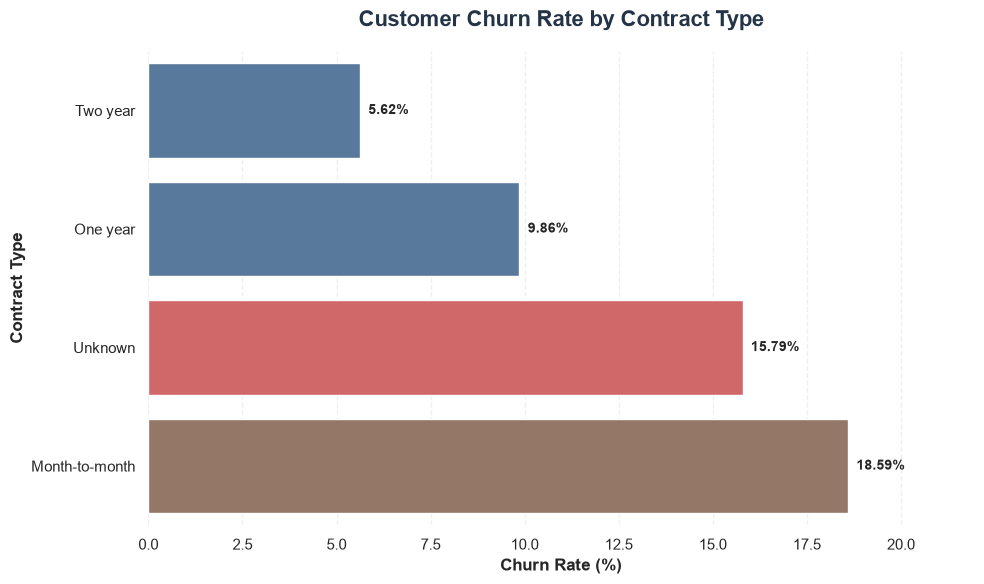

In [65]:
# Calculate churn rate by contract type
contract_churn = (df.groupby("contract_type")["churn_flag"].mean().mul(100).sort_values())

# Plot style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=contract_churn.values, y=contract_churn.index, hue=contract_churn.index, palette=colors[:len(contract_churn)],
    legend=False)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=6, fontsize=10, fontweight="bold")

# Title and labels
plt.title("Customer Churn Rate by Contract Type", fontsize=16, fontweight="bold", color="#243447", pad=18)
plt.xlabel("Churn Rate (%)", fontsize=12, fontweight="bold")
plt.ylabel("Contract Type", fontsize=12, fontweight="bold")
# Clean design
sns.despine(left=True, bottom=True)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.grid(axis="y", visible=False)
plt.xlim(0, contract_churn.max() * 1.18)

plt.tight_layout()
plt.show()


# Insight :- Month to month customers churn rate is 18.59% which is more than as compare to other contarct type  

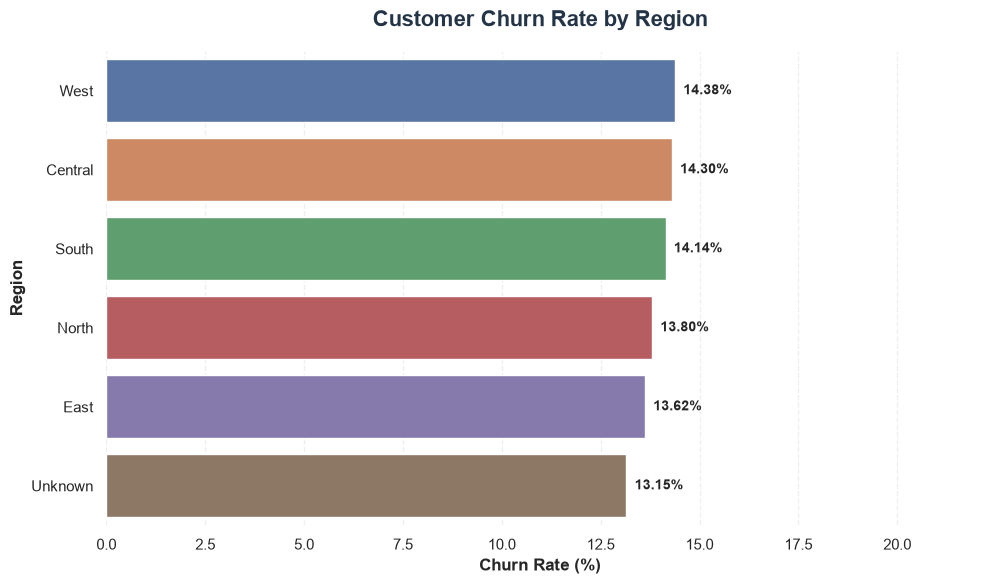

In [83]:
# Calculate churn rate by region-wise
Region_churn = (df.groupby("region")["churn_flag"].mean().mul(100).round(2).sort_values(ascending=False))
   
#plot style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10,6))
ax = sns.barplot(x=Region_churn.values, y= Region_churn.index, hue= Region_churn.index,  
    legend=False)

# add percentage label

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=6, fontsize=10, fontweight="bold")

# Title and labels
plt.title("Customer Churn Rate by Region", fontsize=16, fontweight="bold", color="#243447", pad=18)
plt.xlabel("Churn Rate (%)", fontsize=12, fontweight="bold")
plt.ylabel("Region", fontsize=12, fontweight="bold")

# Clean design
sns.despine(left=True, bottom=True)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.grid(axis="y", visible=False)
plt.xlim(0, contract_churn.max() * 1.18)

plt.tight_layout()
plt.show()

# Insight :- There is most churned customers are from west region 14.38% 

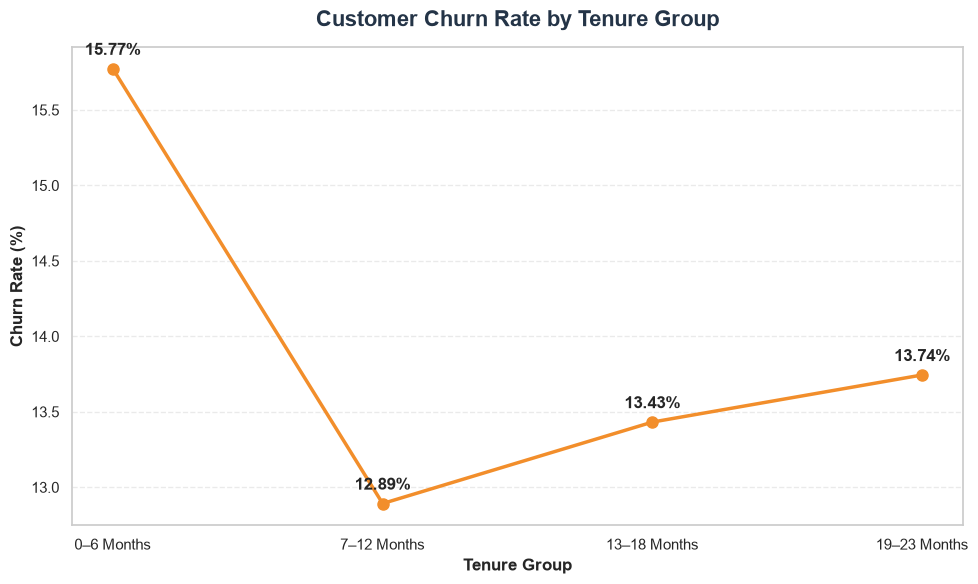

In [89]:
# Step 1: Divide tenure into groups
bins = [0, 6, 12, 18, 23]
labels = ["0–6 Months", "7–12 Months", "13–18 Months", "19–23 Months"]
df["tenure_group"] = pd.cut(df["tenure_months"], bins=bins, labels=labels, include_lowest=True)

# Step 2: Calculate churn rate for each group
tenure_churn = (df.groupby("tenure_group", observed=False)["churn_flag"].mean().mul(100))

# Step 3: Create the line plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
plt.plot(tenure_churn.index.astype(str),tenure_churn.values, color="#F28E2B",marker="o",markersize=8,linewidth=2.5)

# Step 4: Add labels to each point
for i, value in enumerate(tenure_churn.values):
    plt.annotate(f"{value:.2f}%", (i, value), textcoords="offset points", xytext=(0, 10),ha="center",fontweight="bold")

# Step 5: Titles and styling
plt.title("Customer Churn Rate by Tenure Group",fontsize=16,fontweight="bold",color="#243447",pad=15)
plt.xlabel("Tenure Group", fontsize=12, fontweight="bold")
plt.ylabel("Churn Rate (%)", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# insight :- 0 to 6 months has at least overall 15.77% customer churn rate

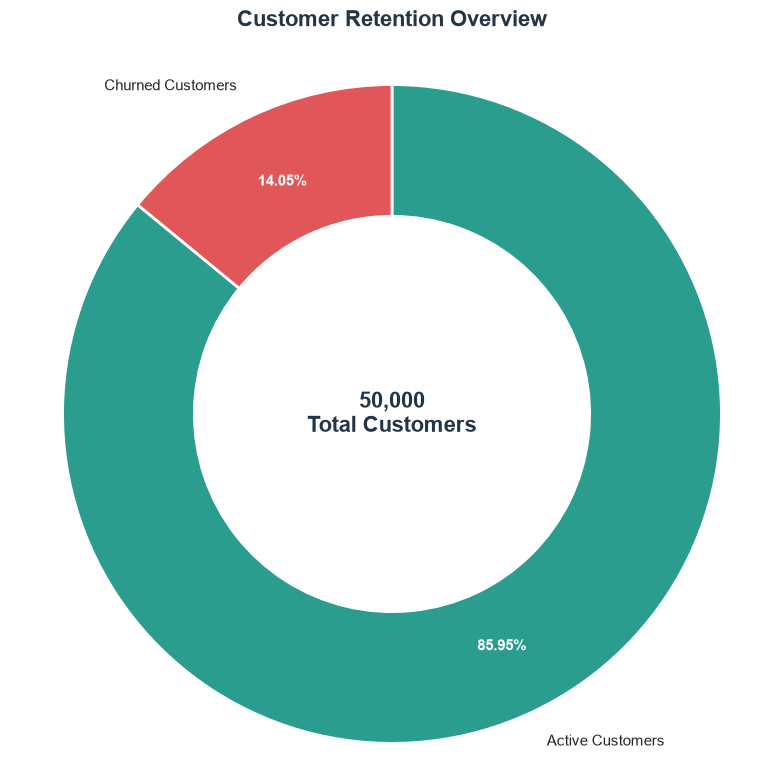

In [93]:
# Step 1: Calculate customer counts
churn_counts = df["churn_flag"].value_counts().reindex([0, 1], fill_value=0)

labels = ["Active Customers", "Churned Customers"]
values = churn_counts.values

# Step 3: Create donut chart
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(values, labels=labels, autopct="%1.2f%%", startangle=90, counterclock=False, pctdistance=0.78,
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11})

# Step 4: Style percentage labels
for text in autotexts:
    text.set_fontweight("bold")
    text.set_color("white")
    text.set_fontsize(11)

# Step 5: Add total customers in the centre
ax.text(0, 0,f"{len(df):,}\nTotal Customers",ha="center", va="center", fontsize=16, fontweight="bold", color="#243447")
# Step 6: Title
ax.set_title("Customer Retention Overview", fontsize=16, fontweight="bold", color="#243447", pad=20)
ax.axis("equal")
plt.tight_layout()
plt.show()


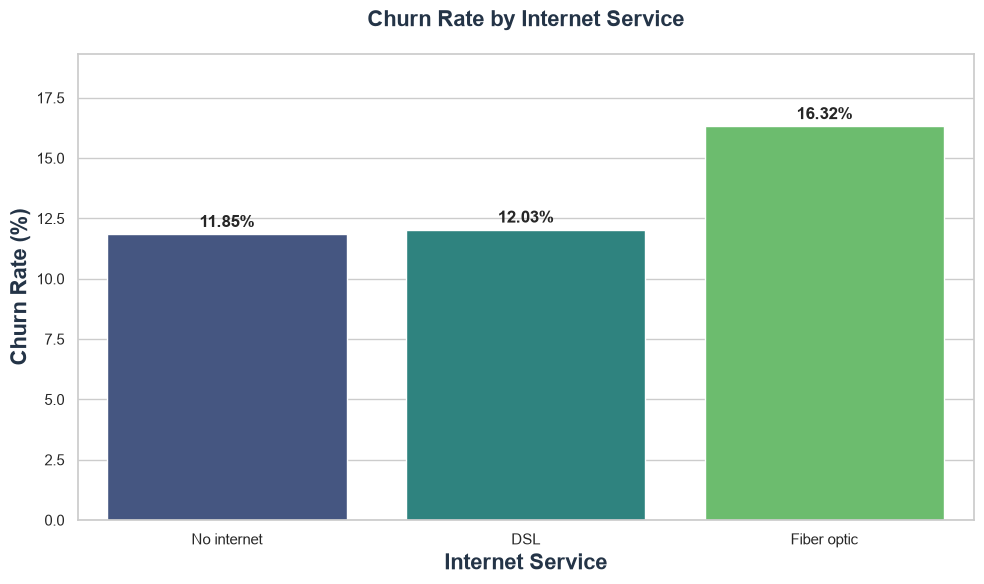

In [106]:
churn = df.groupby("internet_service")["churn_flag"].mean().mul(100).sort_values()

plt.figure(figsize=(10,6))
ax = sns.barplot(x=churn.index, y=churn.values, hue=churn.index,  palette="viridis", legend=False)

# Har bar ke upar percentage
for bar in ax.patches:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.3, f"{height:.2f}%", ha="center", fontweight="bold")

ax.set_ylim(0, churn.max() + 3)
plt.title("Churn Rate by Internet Service" ,fontsize=16, fontweight="bold", color="#243447", pad=20)
plt.xlabel("Internet Service", fontsize=16, fontweight="bold", color="#243447")
plt.ylabel("Churn Rate (%)", fontsize=16, fontweight="bold", color="#243447")
plt.tight_layout()
plt.show()

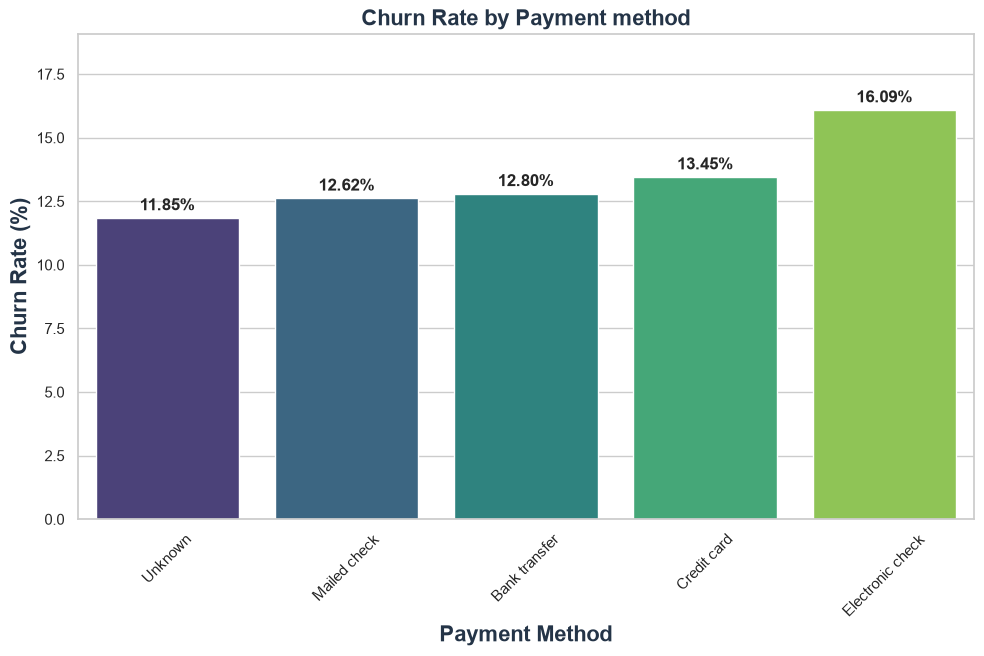

In [110]:
churn = df.groupby("payment_method")["churn_flag"].mean().mul(100).sort_values()

plt.figure(figsize=(10,6))
ax = sns.barplot(x=churn.index, y=churn.values, hue=churn.index,  palette="viridis", legend=False)

# Har bar ke upar percentage
for bar in ax.patches:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.3, f"{height:.2f}%", ha="center", fontweight="bold")

ax.set_ylim(0, churn.max() + 3)
plt.title("Churn Rate by Payment method", fontsize=16, fontweight="bold", color="#243447")
plt.xlabel("Payment Method" , fontsize=16, fontweight="bold", color="#243447")
plt.ylabel("Churn Rate (%)",fontsize=16, fontweight="bold", color="#243447")
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

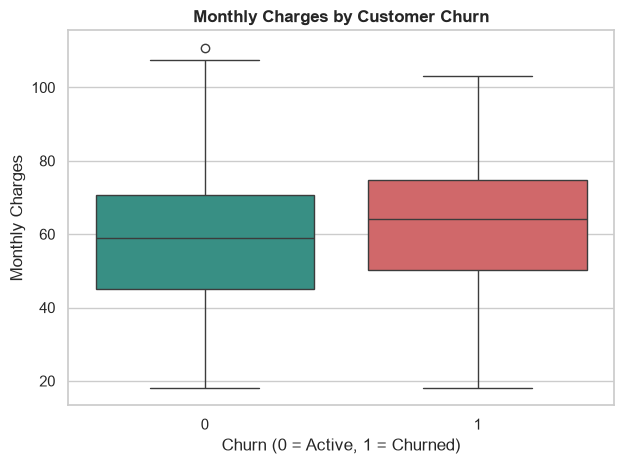

In [117]:
sns.boxplot(data=df, x="churn_flag", y="monthly_charges", hue="churn_flag",
            palette=["#2A9D8F", "#E15759"], legend=False)

plt.title("Monthly Charges by Customer Churn", fontweight="bold")
plt.xlabel("Churn (0 = Active, 1 = Churned)")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [118]:
df.groupby("churn_flag")["monthly_charges"].describe()

,count,mean,std,min,25%,50%,75%,max
churn_flag,,,,,,,,
0,42967.0,57.270094,17.70984,18.0,45.160,59.03,70.73,110.88
1,7018.0,61.616207,17.56899,18.0,50.135,64.16,74.81,103.06


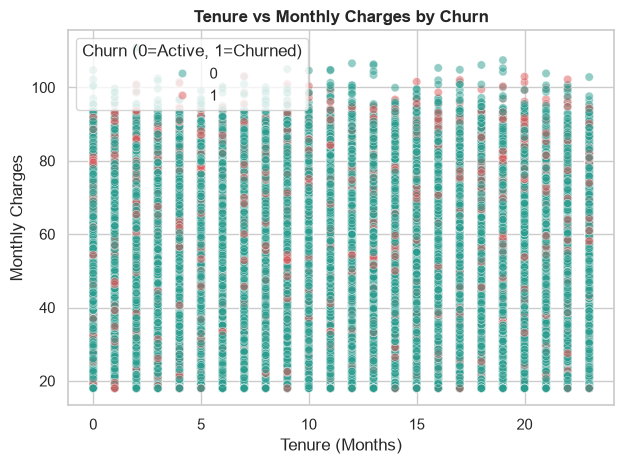

In [112]:
sns.scatterplot(data=df, x="tenure_months", y="monthly_charges", hue="churn_flag", palette={0: "#2A9D8F", 1: "#E15759"},
                alpha=0.5)
plt.title("Tenure vs Monthly Charges by Churn", fontweight="bold")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Churn (0=Active, 1=Churned)")
plt.tight_layout()
plt.show()

In [120]:
df[['tenure_months','monthly_charges']].corr()

,tenure_months,monthly_charges
tenure_months,1.000000,0.000377
monthly_charges,0.000377,1.000000


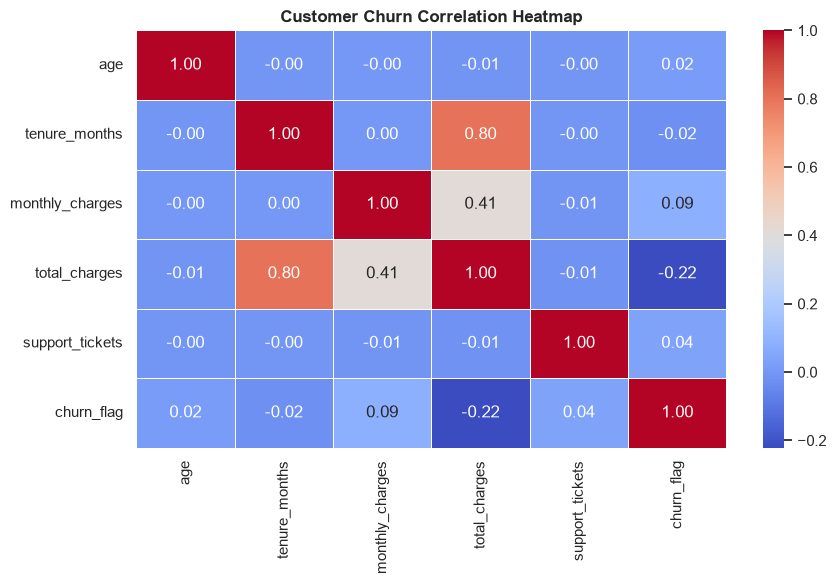

In [113]:
cols = ["age", "tenure_months", "monthly_charges",
        "total_charges", "support_tickets", "churn_flag"]

plt.figure(figsize=(9, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Customer Churn Correlation Heatmap", fontweight="bold")
plt.tight_layout()
plt.show()

In [121]:
print("EDA(Exploratory Data Analysis has completed..!✅)")

EDA(Exploratory Data Analysis has completed..!✅)
